In [21]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

import os
halogen_dir = os.getcwd()
os.chdir('../')
from edautils.plot import ternary_ax, ternary
from edautils.plot import calc_portion, energy_bar_ax
from edautils.plot import grouped_boxplot_ax, box_plot_data
from edautils.plot import kdeplot, kdeplot_norm
from edautils.plot import plot

os.chdir(halogen_dir)
df = pd.read_csv('halogen_EDA.csv')
# df = raw_df.query('TOTAL < 0')
df.shape

(1318, 43)

In [22]:
print(len(df.query('TOTAL > 0')))  # highest TOTAL = 27.8550
print(len(df.query('TOTAL < 0'))) # lowest TOTAL = -52.9949

254
1064


In [23]:
labels = ['F', 'Cl', 'Br', 'I']

def split_halogen(df):
    dfList = []
    dfList.append(df.query('donortype == "F" & TOTAL < 0'))
    dfList.append(df.query('donortype == "Cl" & TOTAL < 0'))
    dfList.append(df.query('donortype == "Br" & TOTAL < 0'))
    dfList.append(df.query('donortype == "I" & TOTAL < 0'))
    return dfList

In [24]:
plot?

Signature:
plot(
    type,
    args,
    dfs,
    ax,
    cmap_range=[-100, 0.0],
    median=False,
    ratio1=False,
    ratio2=False,
    plot=False,
    kde_norm=False,
)
Docstring:
General Plot Function

Parameters
----------
type: {'ternary', 'bar', 'dist', 'box'}
    Plot types
args: list
    List of arguments for each plot type:
    - 'ternary': (label, index, type, cmap_range)
        - label: str
            type of atom/interaction
        - index: str
            index for ternary plot
        - type: str
            type of ternary plot ('frz_orb_disp', 'elec_orb_disp', 'frz_pol_ct')
    - 'bar': (labels, items)
        - label: list(str)
            type of atom/interaction
        - items: list(str)
            EDA energy components 
    - 'dist': (column, labels, item, palette)
        - column: str
            column of dataframe
        - label: list(str)
            type of atom/interaction
        - item: list(str)
            EDA energy components
        - palette:

# Ternary Plots

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_28274/192543056.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


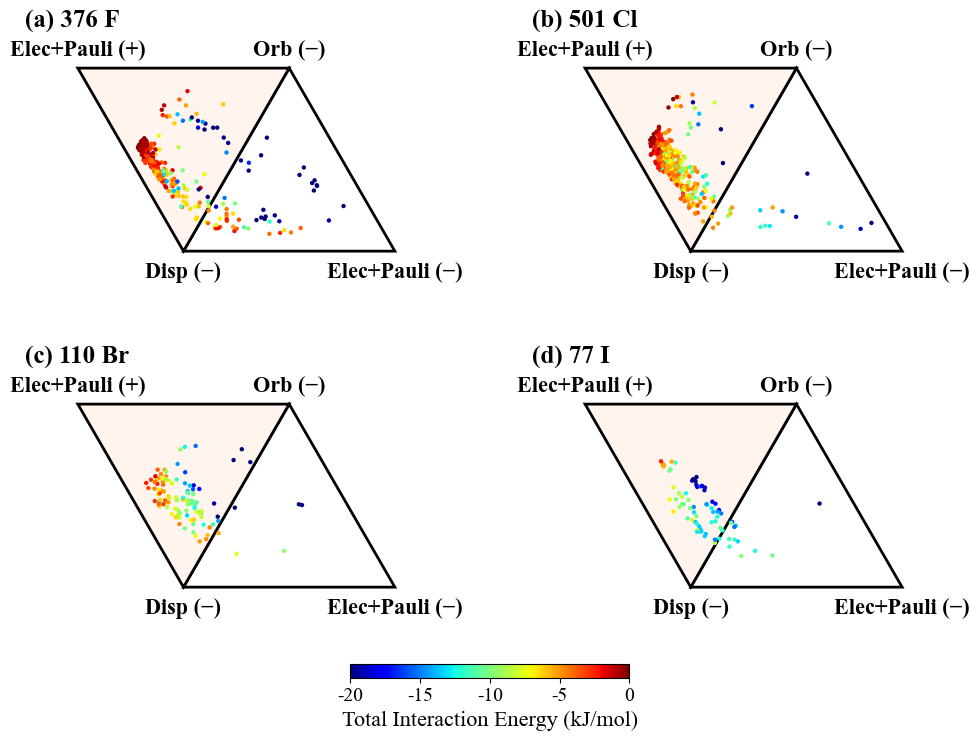

In [25]:
dfs = split_halogen(df)
labels = ['F', 'Cl', 'Br', 'I']
cmap_range = [-20, 0]
types = 'frz_orb_disp'

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
sc = plot('ternary', (labels[0], 'a', types), dfs[0], axes[0,0], cmap_range)
plot('ternary', (labels[1], 'b', types), dfs[1], axes[0,1], cmap_range)
plot('ternary', (labels[2], 'c', types), dfs[2], axes[1,0], cmap_range)
plot('ternary', (labels[3], 'd', types), dfs[3], axes[1,1], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_28274/2156102756.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


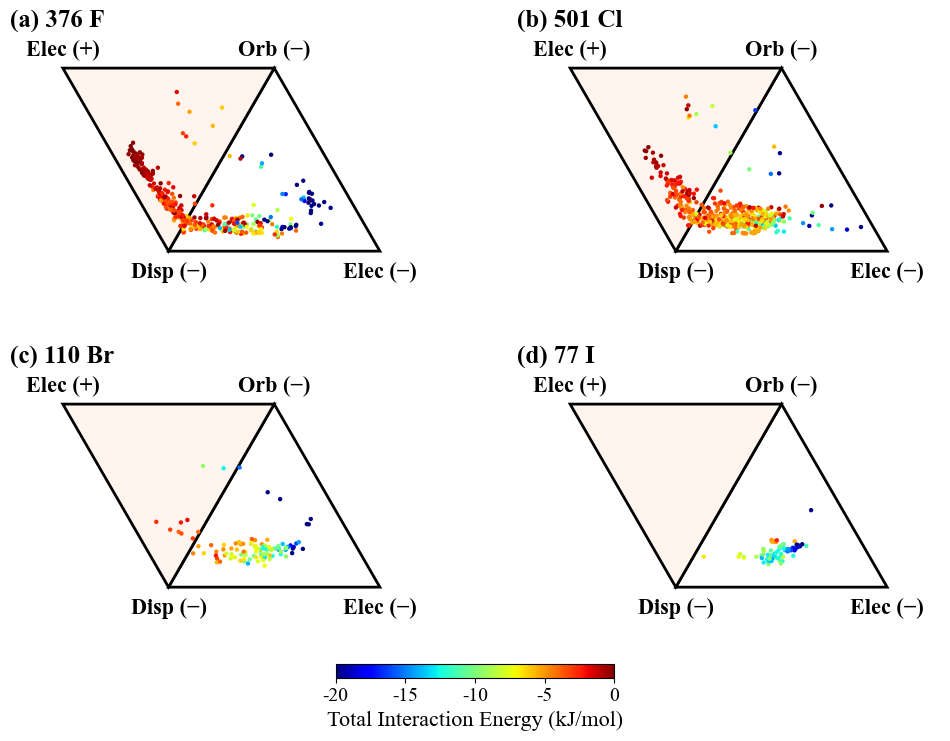

In [26]:
types = 'elec_orb_disp'

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
sc = plot('ternary', (labels[0], 'a', types), dfs[0], axes[0,0], cmap_range)
plot('ternary', (labels[1], 'b', types), dfs[1], axes[0,1], cmap_range)
plot('ternary', (labels[2], 'c', types), dfs[2], axes[1,0], cmap_range)
plot('ternary', (labels[3], 'd', types), dfs[3], axes[1,1], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_28274/2830028008.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


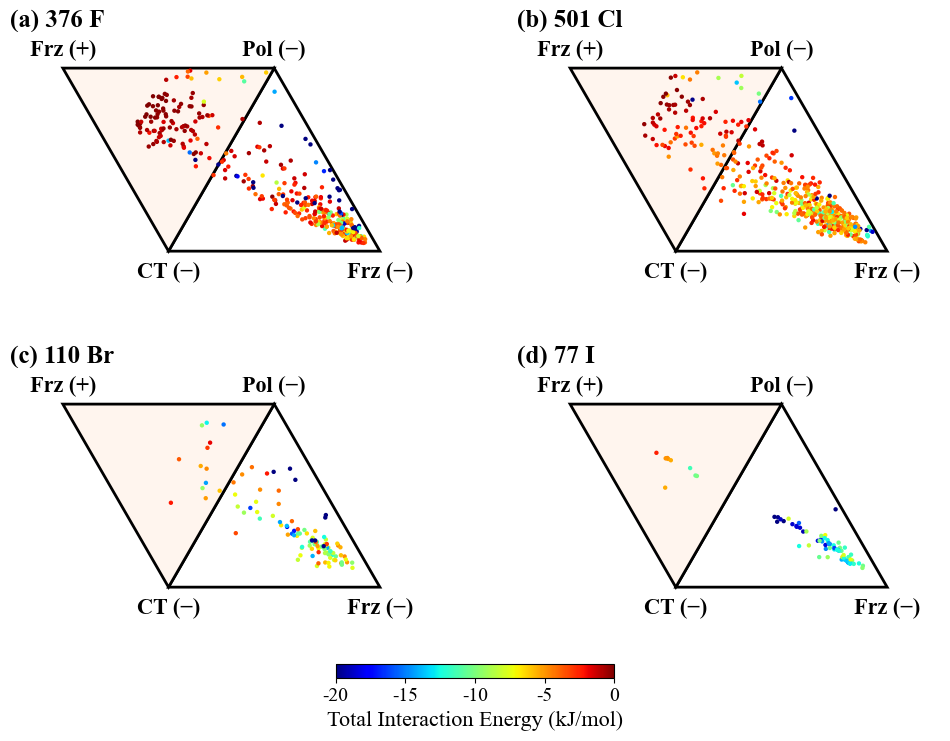

In [27]:
types = 'frz_pol_ct'

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
sc = plot('ternary', (labels[0], 'a', types), dfs[0], axes[0,0], cmap_range)
plot('ternary', (labels[1], 'b', types), dfs[1], axes[0,1], cmap_range)
plot('ternary', (labels[2], 'c', types), dfs[2], axes[1,0], cmap_range)
plot('ternary', (labels[3], 'd', types), dfs[3], axes[1,1], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

# Energy Bar Plots

## Bar Plot Ratio type formulation

### ratio1: $R_1 = \frac{\sum_{i} E_{i}^{(t)}}{\sum_{i} E_{i}^{(\text{total})}}$

### ratio2: $R_2 = \sum_{i} \frac{E_{i}^{(t)}}{E_{i}^{(\text{total})}}$

len: list(map(len, dfs))
len: list(map(len, dfs))


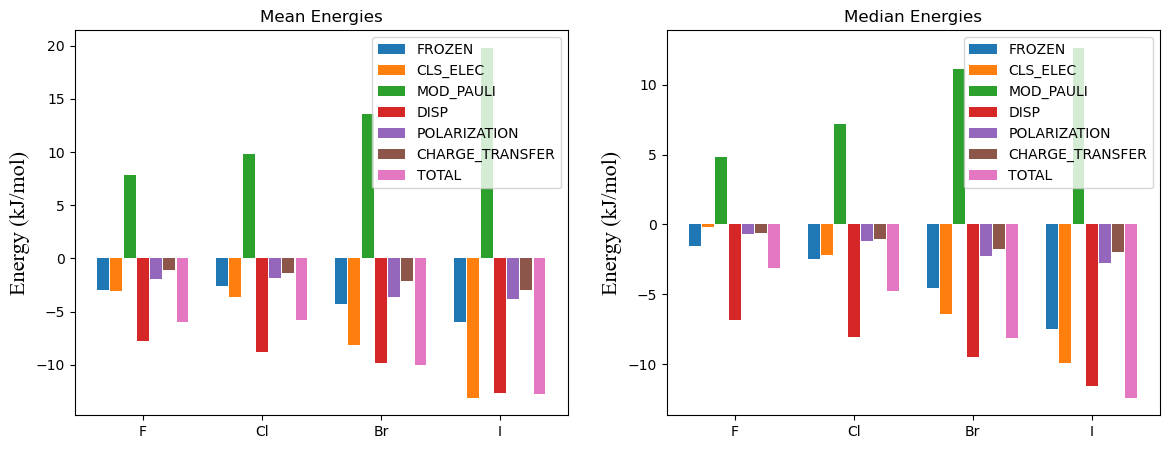

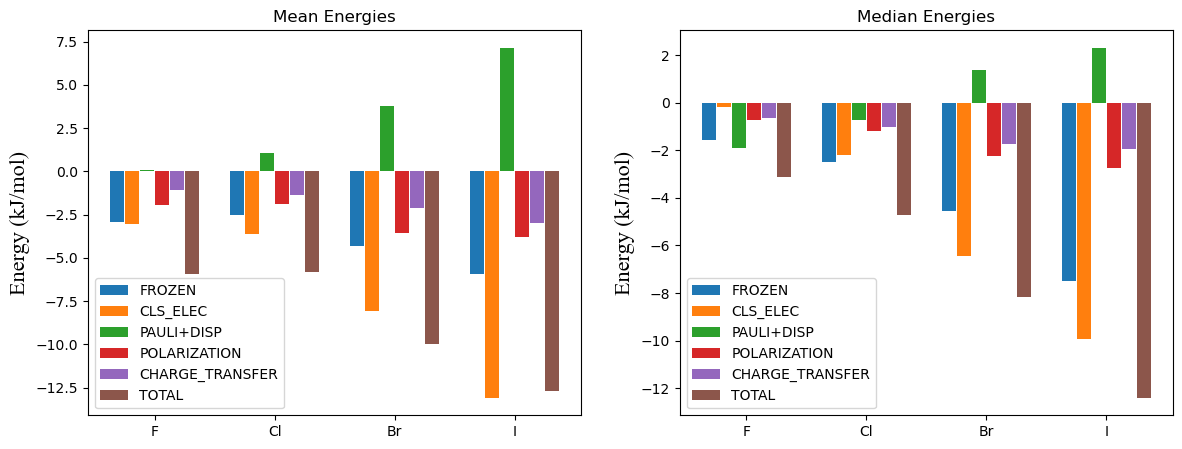

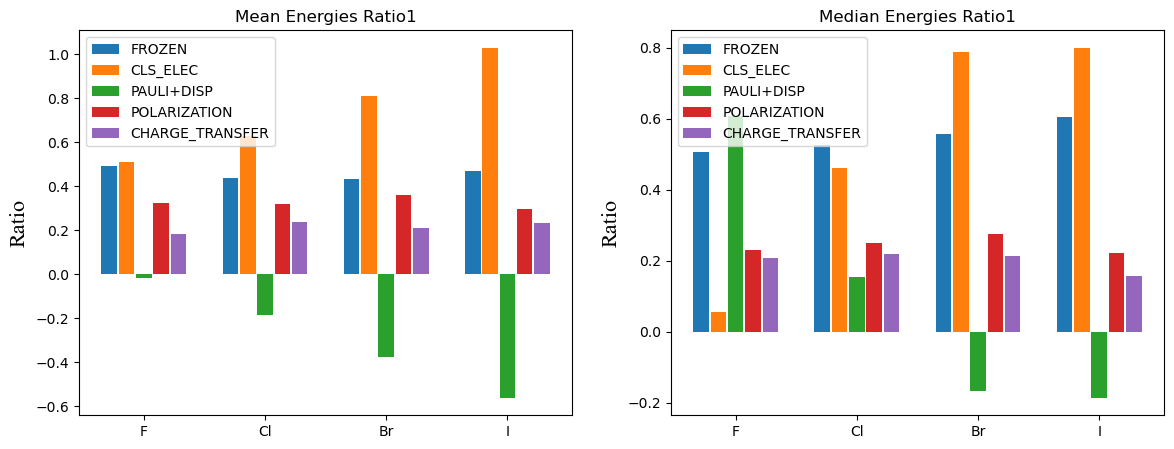

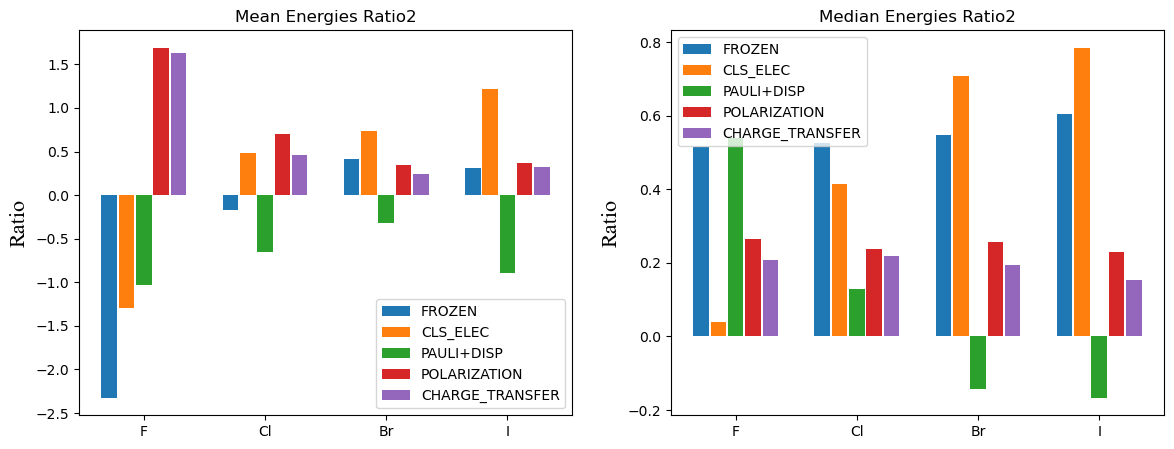

In [28]:
labels = ['F', 'Cl', 'Br', 'I']
items = [
    'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    # 'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]
dfs = split_halogen(df)

print(f'len: list(map(len, dfs))')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1], median=True)
axes[1].set_title('Median Energies')
plt.savefig('bar_Energy_all.png')

items = [
    'FROZEN', 
    'CLS_ELEC', 
    # 'MOD_PAULI', 
    # 'DISP', 
    'PAULI+DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]
dfs = split_halogen(df)

print(f'len: list(map(len, dfs))')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs, axes[1], median=True)
axes[1].set_title('Median Energies')
plt.savefig('bar_Energy_pauli+disp.png')


items = [
    'FROZEN', 
    'CLS_ELEC', 
    # 'MOD_PAULI', 
    # 'DISP', 
    'PAULI+DISP',
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0], ratio1=True)
axes[0].set_title('Mean Energies Ratio1')
plot('bar', (labels, items), dfs, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies Ratio1')
plt.savefig('bar_ratio1_all_pauli+disp.png')

items = [
    'FROZEN', 
    'CLS_ELEC', 
    # 'MOD_PAULI', 
    # 'DISP', 
    'PAULI+DISP',
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
] 

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs, axes[0], ratio2=True)
axes[0].set_title('Mean Energies Ratio2')
plot('bar', (labels, items), dfs, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies Ratio2')
plt.savefig('bar_ratio2_all_pauli+disp.png')

len: list(map(len, dfs))


Text(0.5, 1.0, 'Mean Energies Ratio2')

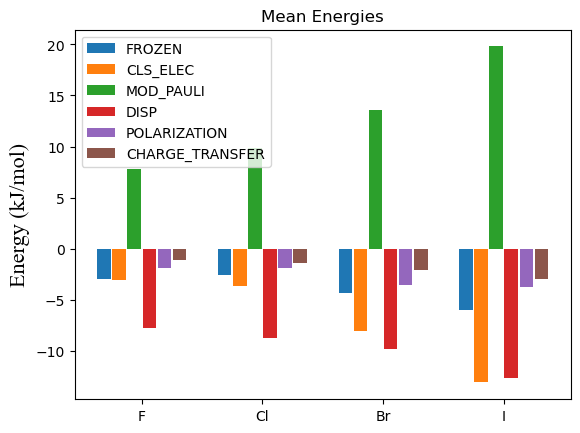

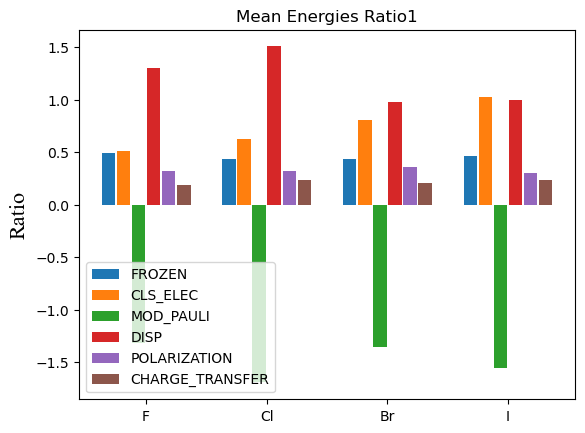

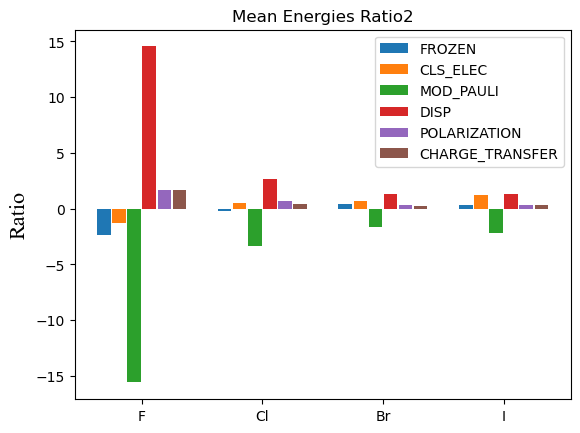

In [29]:
df_outlier = df

df_outlier.drop(index=322) # F electrostatic outlier
df_outlier.drop(index=1027) # F electrostatic outlier
# df_outlier.drop(index=331) # Cl electrostatic outlier
labels = ['F', 'Cl', 'Br', 'I']
items = [
    'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    # 'TOTAL'
]
dfs = split_halogen(df)

print(f'len: list(map(len, dfs))')

fig, axes = plt.subplots()
plot('bar', (labels, items), dfs, axes)
axes.set_title('Mean Energies')

fig, axes = plt.subplots()
plot('bar', (labels, items), dfs, axes, ratio1=True)
axes.set_title('Mean Energies Ratio1')

fig, axes = plt.subplots()
plot('bar', (labels, items), dfs, axes, ratio2=True)
axes.set_title('Mean Energies Ratio2')

# Box Plot

Text(0.5, 1.0, 'Box Plot')

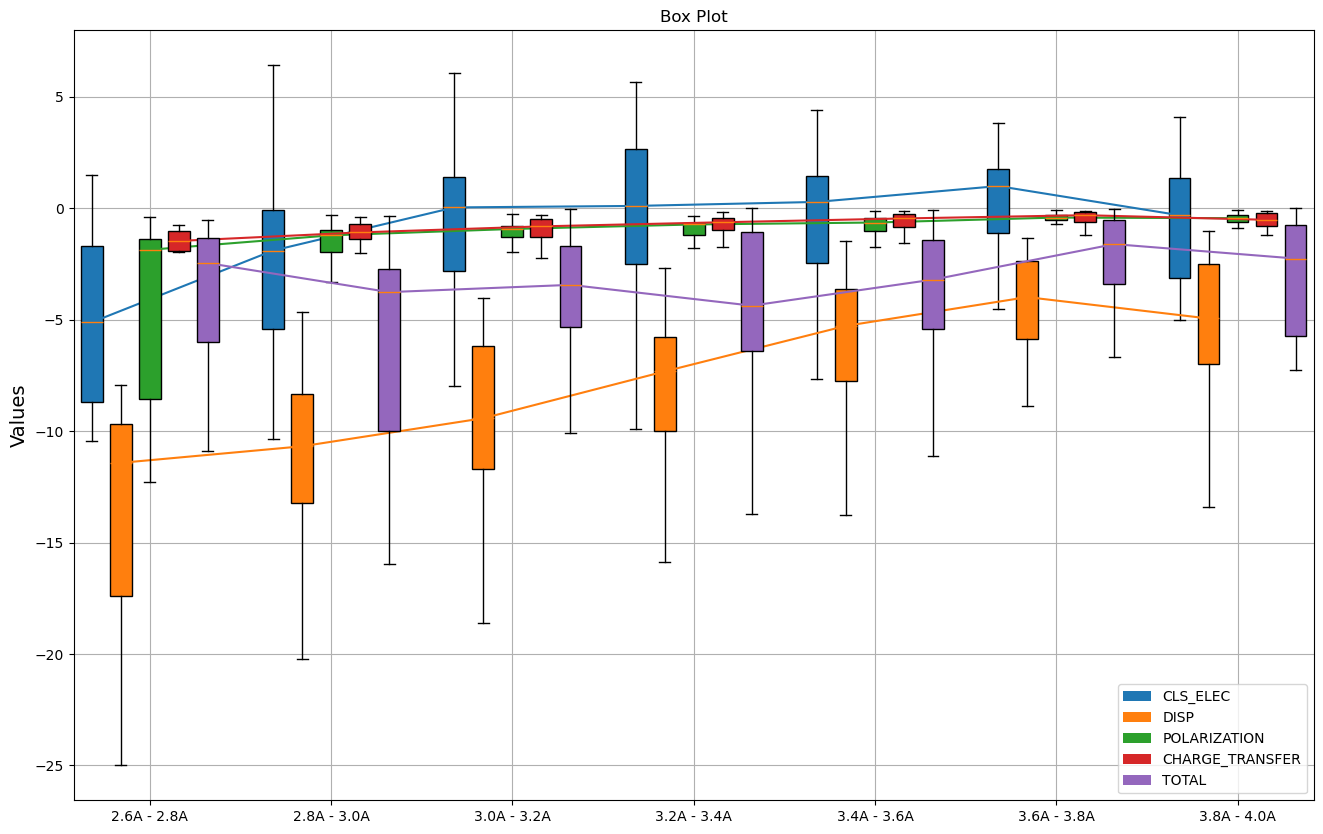

In [30]:
xlabels = ['2.6A - 2.8A', '2.8A - 3.0A', '3.0A - 3.2A', '3.2A - 3.4A', '3.4A - 3.6A', '3.6A - 3.8A', '3.8A - 4.0A']
items = [
    'CLS_ELEC', 
    'DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

dists = np.arange(2.6, 4.2, 0.2).tolist()

fig, ax = plt.subplots(figsize=(16, 10))
plot('box', (dists, xlabels, items), dfs[0], ax, plot=True)
ax.set_title('Box Plot')

# Dist Plot

In [31]:
def split_eda(df):
    dfList = []
    frozen = df.query("TOTAL < 0 & FROZEN < 20 & FROZEN > -20")
    elec = df.query("TOTAL < 0 & CLS_ELEC > -50 & CLS_ELEC < 10")
    pauli = df.query("TOTAL < 0")
    disp = df.query("TOTAL < 0")
    pol = df.query("TOTAL < 0 & POLARIZATION > -10")
    ct = df.query("TOTAL < 0 & CHARGE_TRANSFER > -10")
    total = df.query("TOTAL < 0 & TOTAL > -50")
    return [frozen, elec, pauli, disp, pol, ct, total]

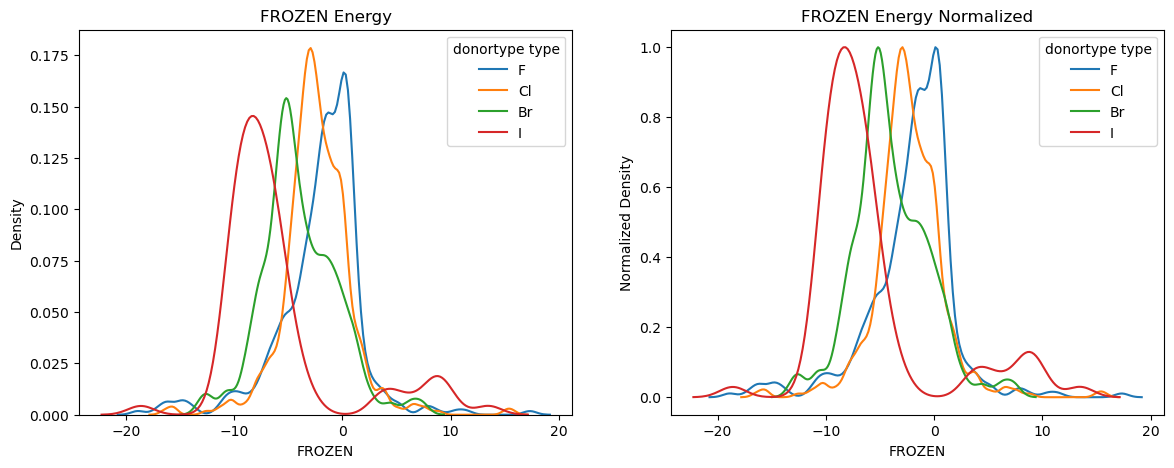

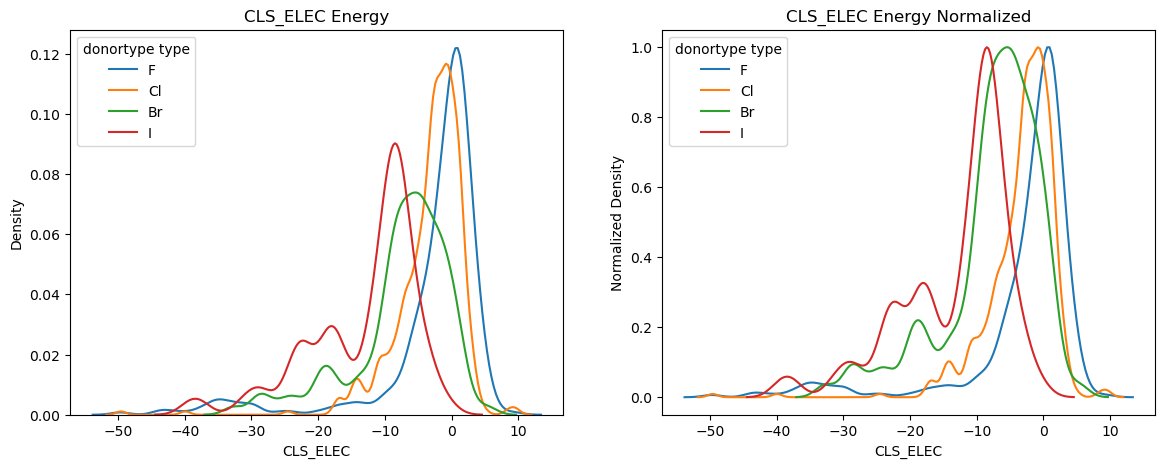

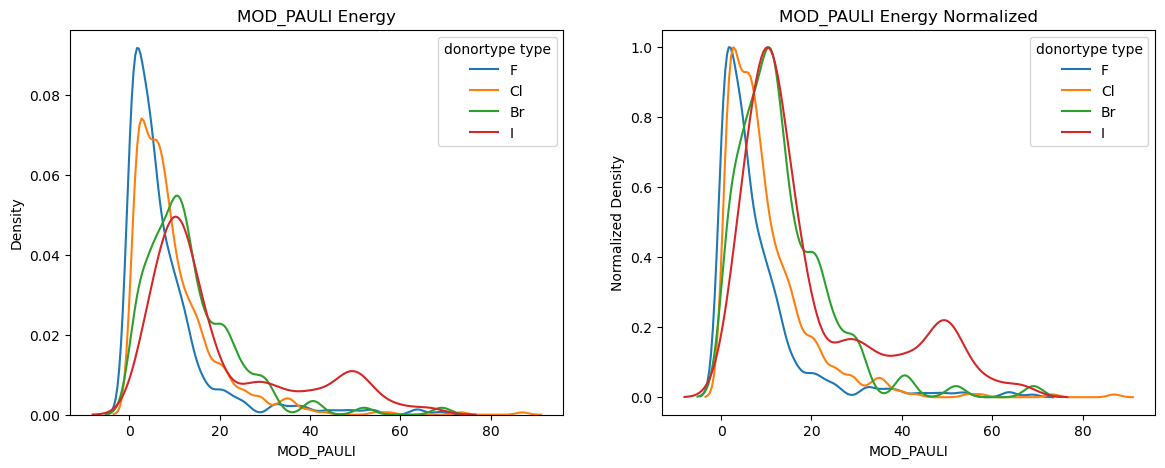

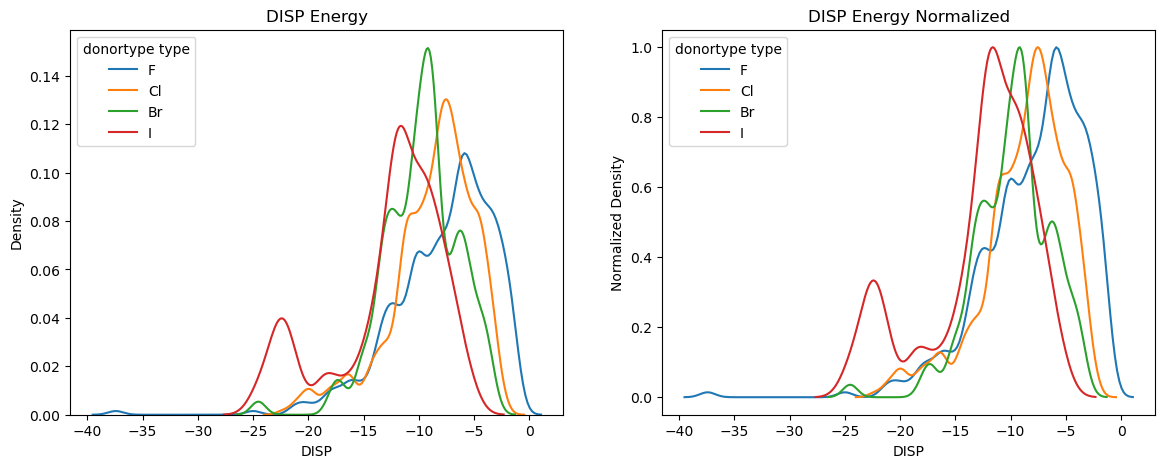

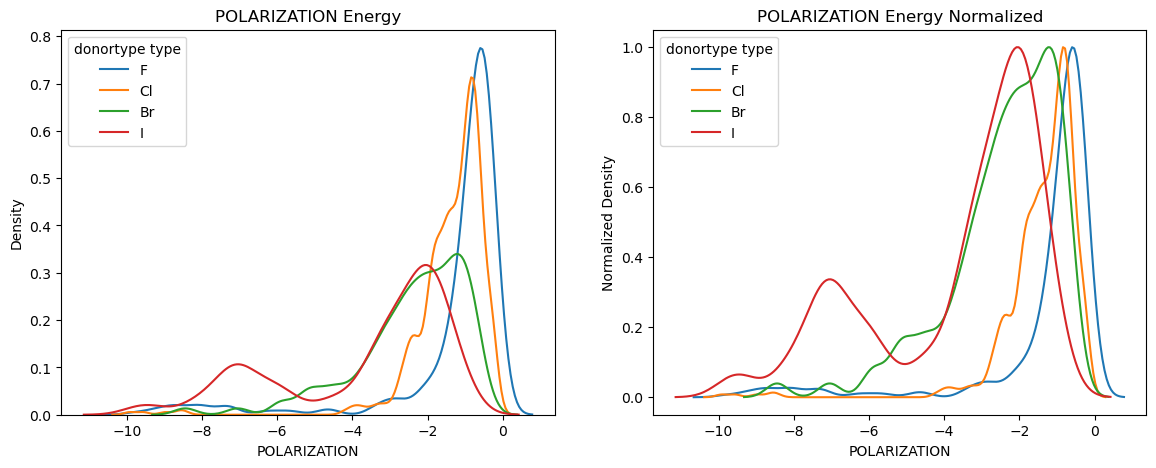

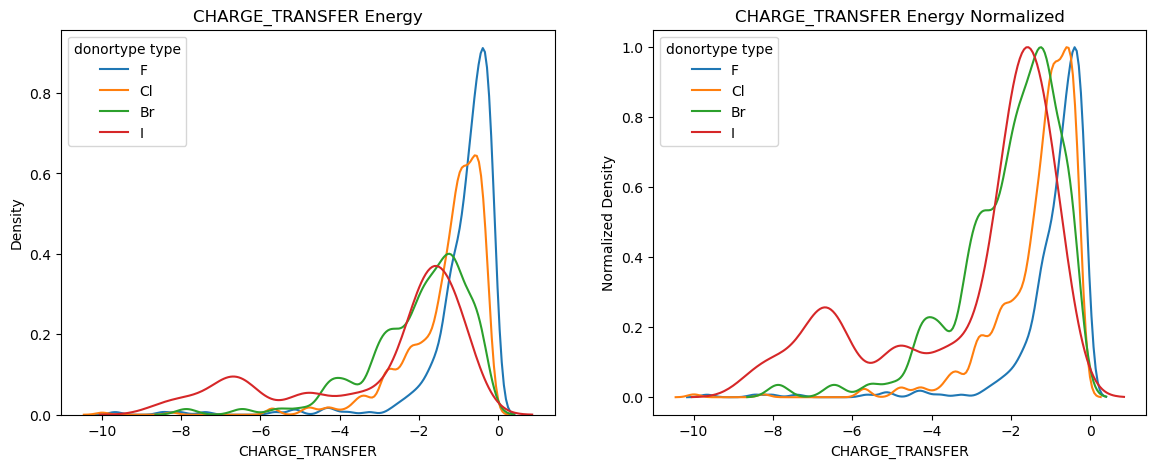

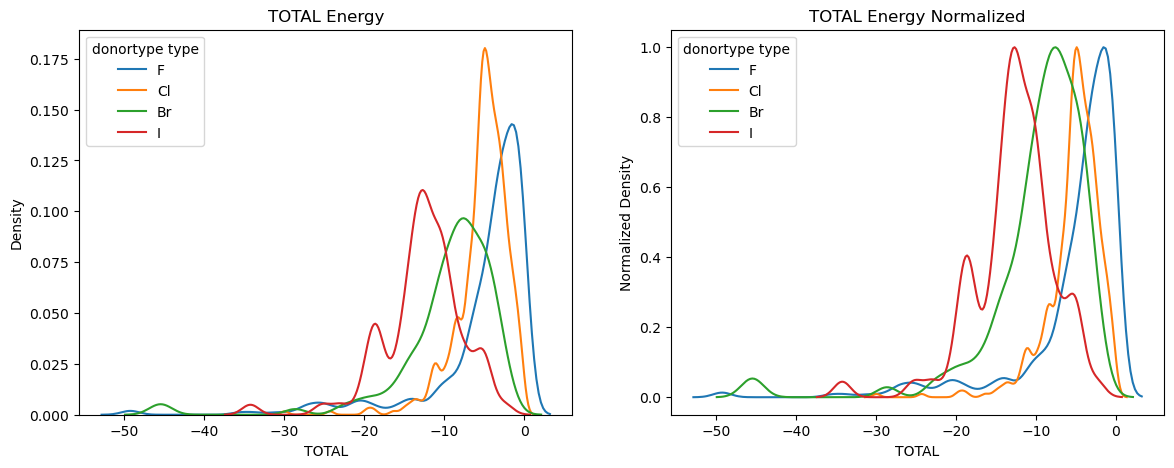

In [32]:
palette = sns.color_palette(n_colors=len(labels))
eda_dfs = split_eda(df)
items = [
    'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

for index, df in enumerate(eda_dfs):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    plot('dist', ('donortype', labels, items[index], palette), df, axes[0])
    plot('dist', ('donortype', labels, items[index], palette), df, axes[1], kde_norm=True)
    plt.savefig(f'Visualizations/dist_{items[index]}.png')



# Attatched Ligand Group F and Cl

In [33]:
from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from openbabel import openbabel
from tqdm import tqdm

dataset_dir = '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset'
df = pd.read_csv("halogen_EDA.csv", index_col=0)

In [36]:
alkyl = '[CX4:1]([F,Cl,Br,I:2])'
ring = '[c:1]-[F,Cl,Br,I:2]'

patts = [alkyl, ring]
patts = list(map(Chem.MolFromSmarts, patts))

def find_groups(mol, idx):    
    for index, patt in enumerate(patts):
        for sub in mol.GetSubstructMatches(patt):
            if sub[1] == (idx - 1):
                if index == 0:
                    C_idx = sub[0]
                    amount = len([sub for sub in mol.GetSubstructMatches(patt) if sub[0] == C_idx])
                    if amount >= 1:
                        return 'alkyl'
                    # if amount == 1:
                    #     return 'alkyl_1'
                    # elif amount == 2:
                    #     return 'alkyl_2'
                    # elif amount == 3:
                    #     return 'alkyl_3'
                elif index == 1:
                    return 'ring'
    return None

groups = []
groupID = []

for index, row in tqdm(df.iterrows()):
    mol = Chem.SDMolSupplier(os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf"), removeHs=False)[0]
    groups.append(find_groups(mol, row['don_idx']))
    groupID.append([row['full_PDBID'], row['subdir'], find_groups(mol, row['don_idx'])])

df['group'] = groups

144it [00:00, 1431.41it/s][18:35:43] Explicit valence for atom # 4 P, 6, is greater than permitted
[18:35:43] ERROR: Could not sanitize molecule ending on line 94
[18:35:43] ERROR: Explicit valence for atom # 4 P, 6, is greater than permitted
145it [00:00, 1406.12it/s]


AttributeError: 'NoneType' object has no attribute 'GetSubstructMatches'

In [35]:
# df_E = df.query('TOTAL < 0')

# F_alkyl1 = df.query('donortype == "F" & TOTAL < 0 & group == "alkyl_1"')
# F_alkyl2 = df.query('donortype == "F" & TOTAL < 0 & group == "alkyl_2"')
# F_alkyl3 = df.query('donortype == "F" & TOTAL < 0 & group == "alkyl_3"')
F_alkyl = df.query('donortype == "F" & TOTAL < 0 & group == "alkyl"')
F_ring = df.query('donortype == "F" & TOTAL < 0 & group == "ring"')

# print(len(F_alkyl1))
# print(len(F_alkyl2))
# print(len(F_alkyl3))
print(len(F_alkyl))
print(len(F_ring))

Cl_alkyl = df.query('donortype == "Cl" & TOTAL < 0 & group == "alkyl"')
Cl_ring = df.query('donortype == "Cl" & TOTAL < 0 & group == "ring"')
print(len(Cl_alkyl))
print(len(Cl_ring))

Br_alkyl = df.query('donortype == "Br" & TOTAL < 0 & group == "alkyl"')
Br_ring = df.query('donortype == "Br" & TOTAL < 0 & group == "ring"')
print(len(Br_alkyl))
print(len(Br_ring))

I_alkyl = df.query('donortype == "I" & TOTAL < 0 & group == "alkyl"')
I_ring = df.query('donortype == "I" & TOTAL < 0 & group == "ring"')
print(len(I_alkyl))
print(len(I_ring))

UndefinedVariableError: name 'group' is not defined

/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_54950/3679324723.py:18: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')
/var/folders/2w/fqycdcd16rx2bbmbqszt3w7h0000gn/T/ipykernel_54950/3679324723.py:37: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')


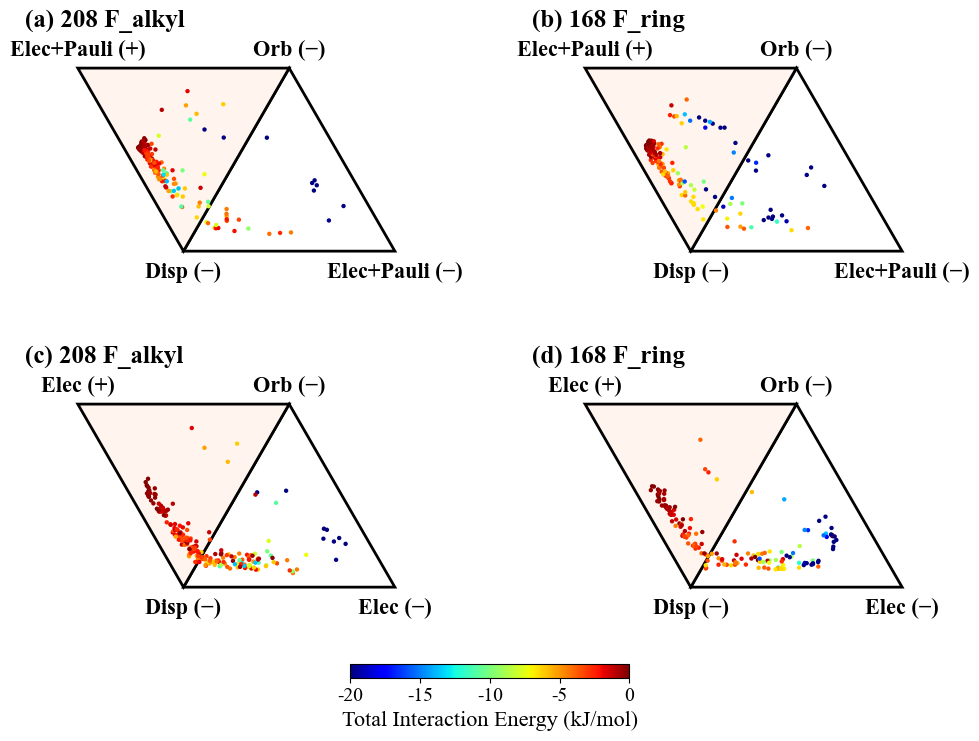

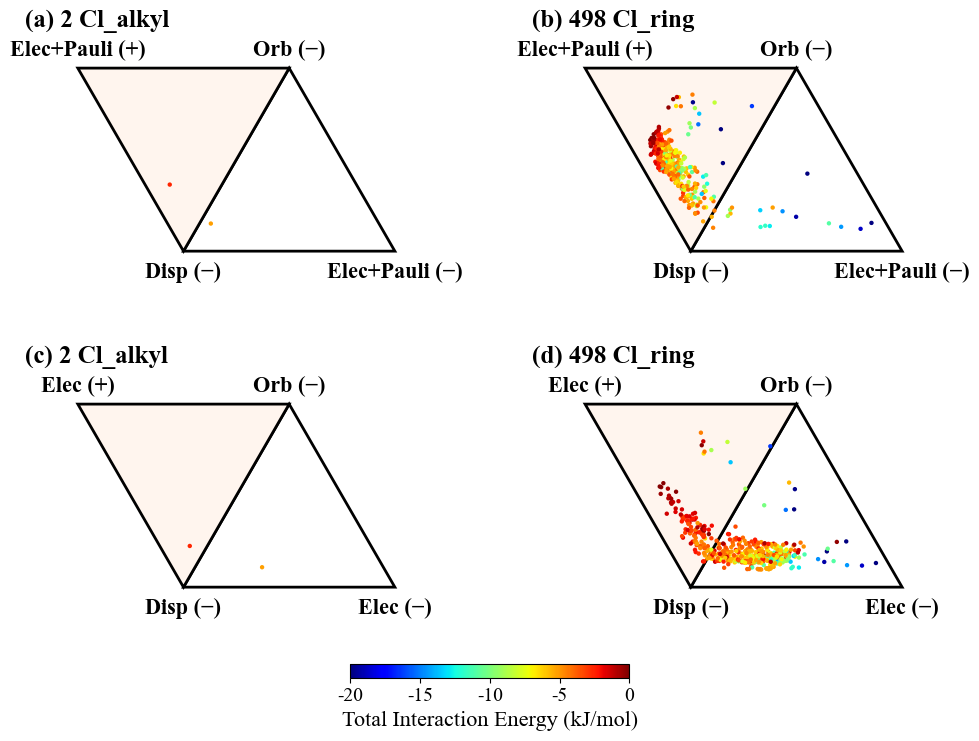

In [ ]:
cmap_range = [-20, 0]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sc = plot('ternary', ('F_alkyl', 'a', 'frz_orb_disp'), F_alkyl, axes[0,0], cmap_range)
plot('ternary', ('F_ring', 'b', 'frz_orb_disp'), F_ring, axes[0,1], cmap_range)
plot('ternary', ('F_alkyl', 'c', 'elec_orb_disp'), F_alkyl, axes[1,0], cmap_range)
plot('ternary', ('F_ring', 'd', 'elec_orb_disp'), F_ring, axes[1,1], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')



fig, axes = plt.subplots(2, 2, figsize=(12, 10))

sc = plot('ternary', ('Cl_alkyl', 'a', 'frz_orb_disp'), Cl_alkyl, axes[0,0], cmap_range)
plot('ternary', ('Cl_ring', 'b', 'frz_orb_disp'), Cl_ring, axes[0,1], cmap_range)
plot('ternary', ('Cl_alkyl', 'c', 'elec_orb_disp'), Cl_alkyl, axes[1,0], cmap_range)
plot('ternary', ('Cl_ring', 'd', 'elec_orb_disp'), Cl_ring, axes[1,1], cmap_range)

cbar = fig.colorbar(
    sc, 
    ax=axes, 
    orientation='horizontal', 
    shrink=0.3,
    pad=0.05
)
cbar.set_label('Total Interaction Energy (kJ/mol)', fontsize=16, family='Times New Roman')
cbar.set_ticklabels(cbar.get_ticks().astype(int), fontsize=14, family='Times New Roman')

Text(0.5, 1.0, 'Median Energies, Ratio2')

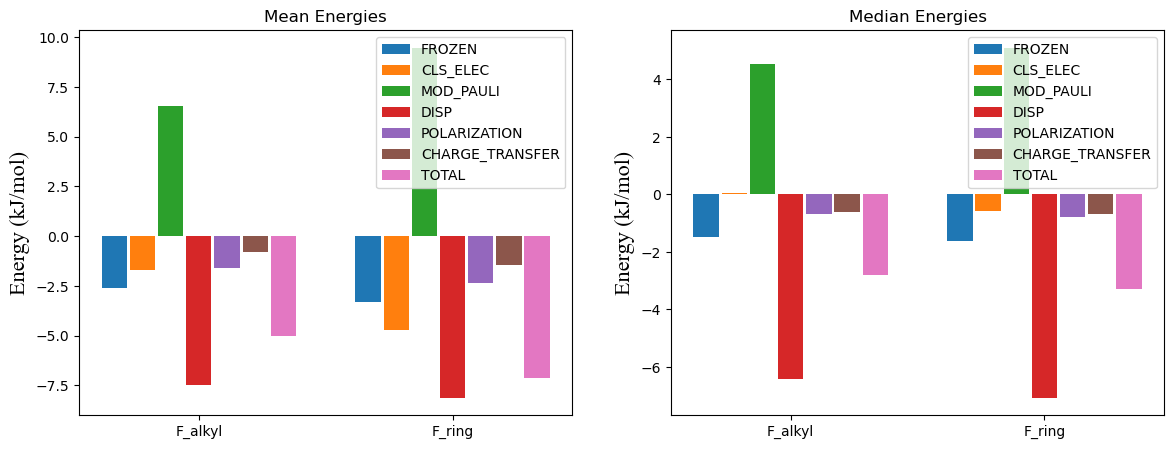

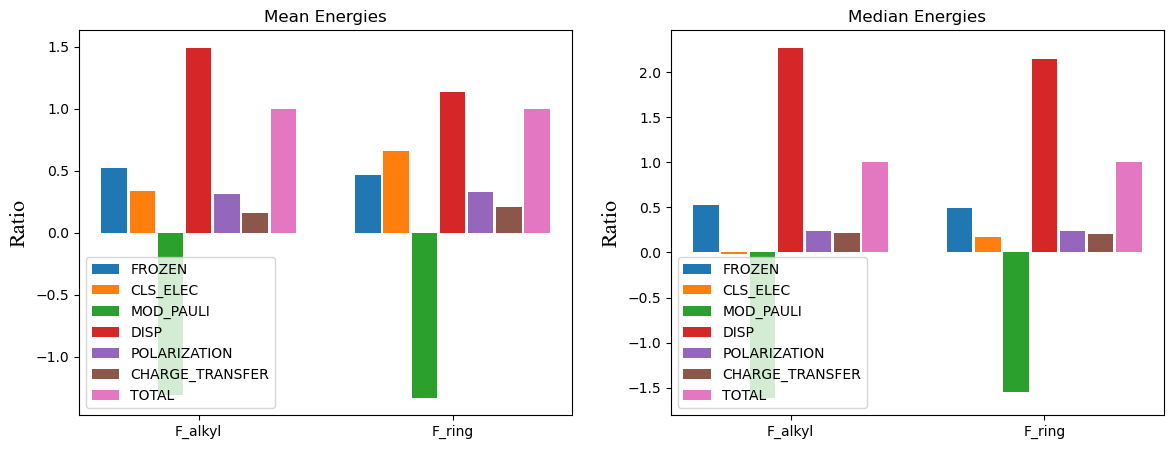

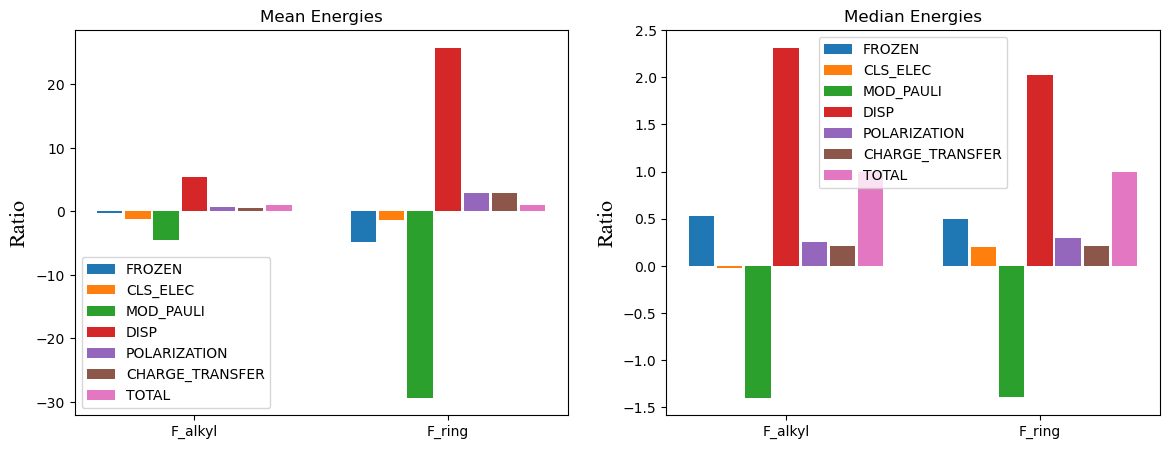

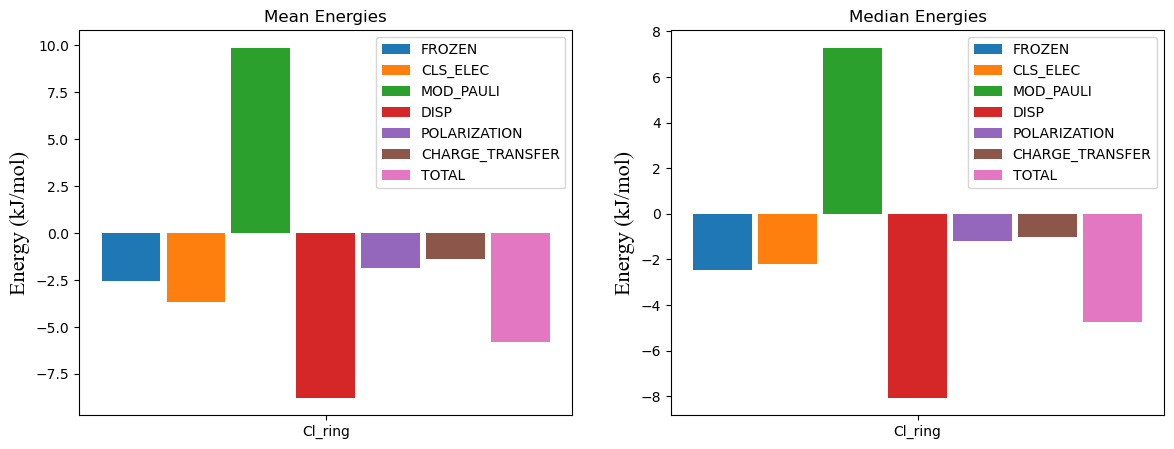

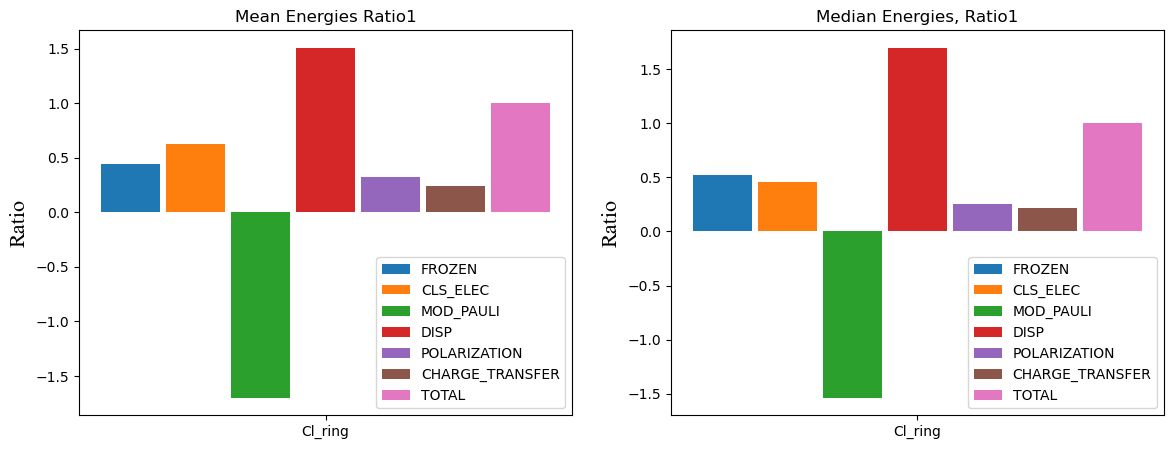

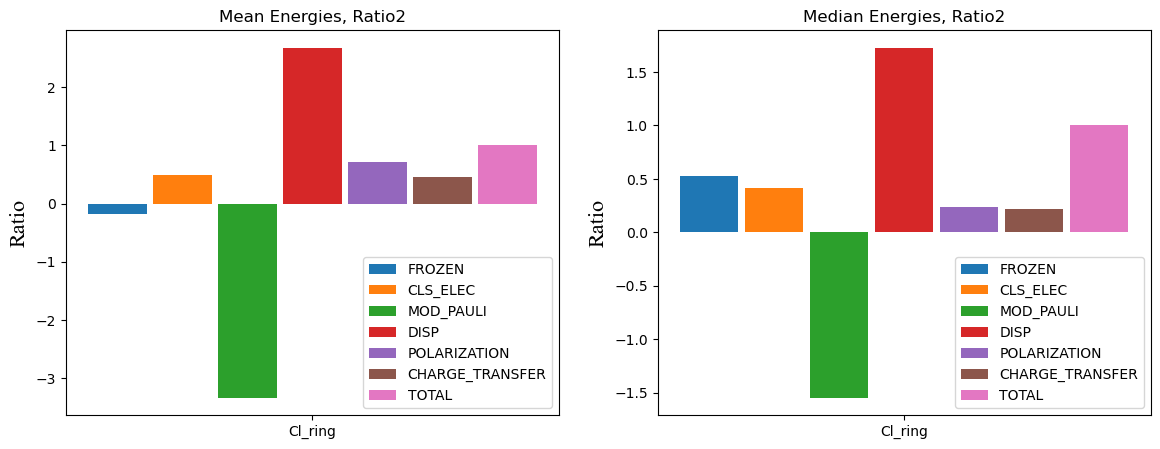

In [ ]:
labels = ['F_alkyl', 'F_ring']
dfs_frag = [F_alkyl, F_ring]
items = [
    'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs_frag, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs_frag, axes[1], median=True)
axes[1].set_title('Median Energies')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs_frag, axes[0], ratio1=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs_frag, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs_frag, axes[0], ratio2=True)
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs_frag, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies')


labels = ['Cl_ring']
dfs_frag = [Cl_ring]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs_frag, axes[0])
axes[0].set_title('Mean Energies')
plot('bar', (labels, items), dfs_frag, axes[1], median=True)
axes[1].set_title('Median Energies')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs_frag, axes[0], ratio1=True)
axes[0].set_title('Mean Energies Ratio1')
plot('bar', (labels, items), dfs_frag, axes[1], median=True, ratio1=True)
axes[1].set_title('Median Energies, Ratio1')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot('bar', (labels, items), dfs_frag, axes[0], ratio2=True)
axes[0].set_title('Mean Energies, Ratio2')
plot('bar', (labels, items), dfs_frag, axes[1], median=True, ratio2=True)
axes[1].set_title('Median Energies, Ratio2')

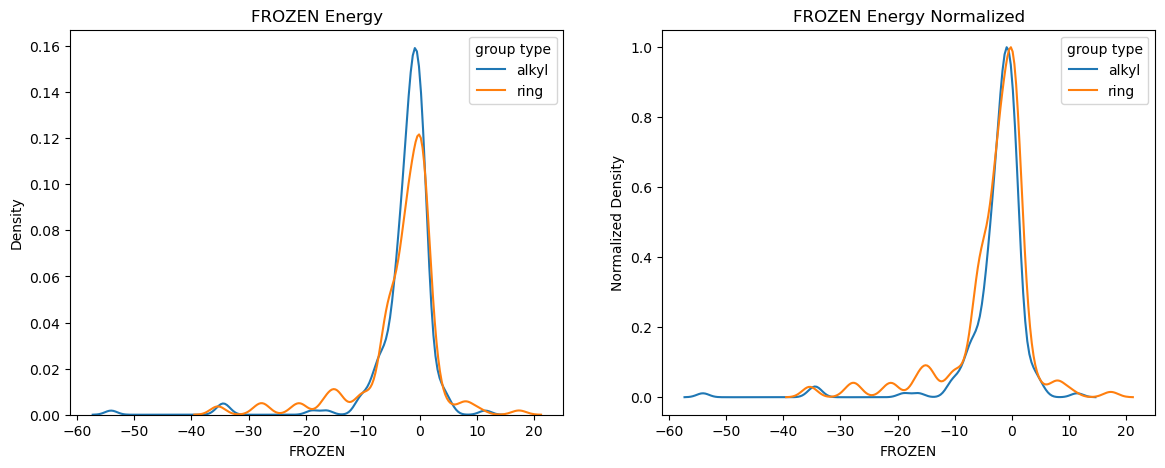

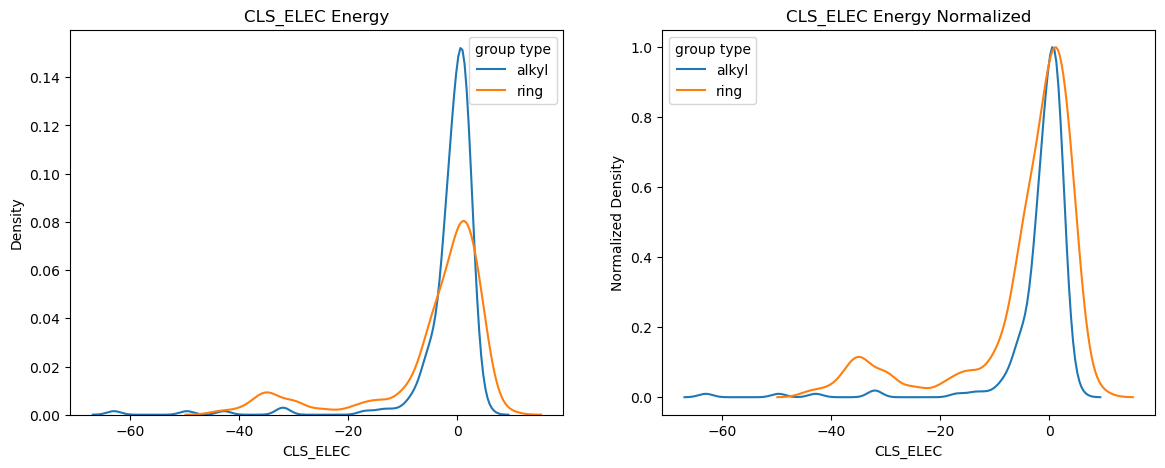

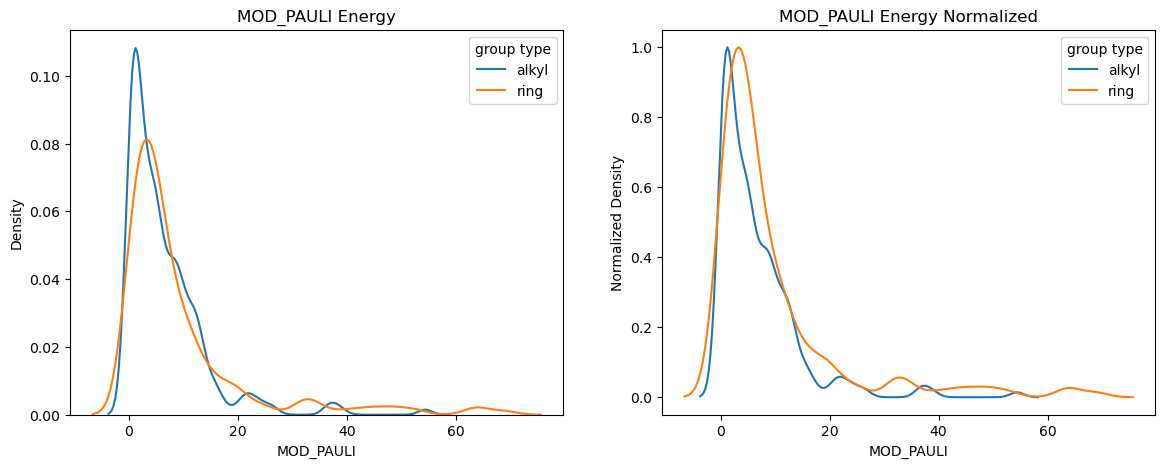

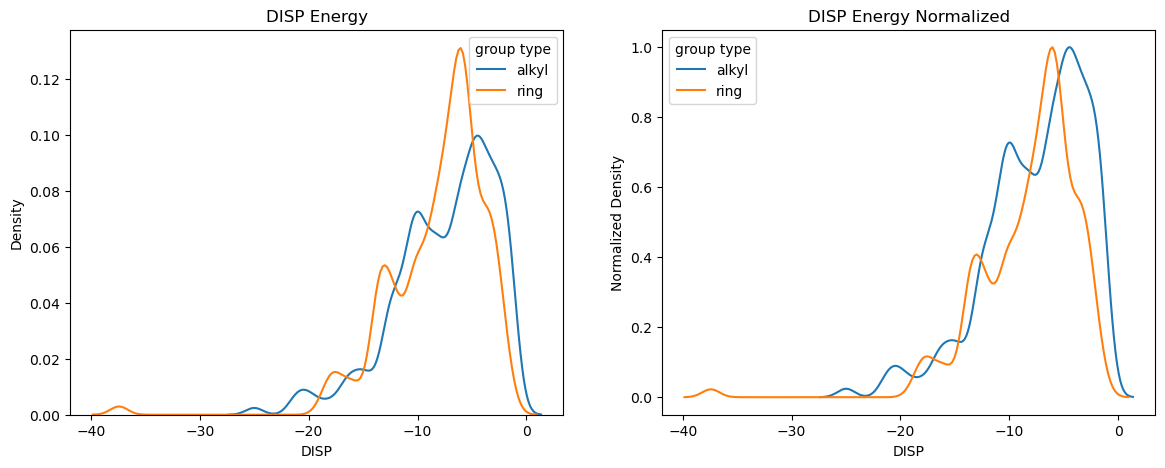

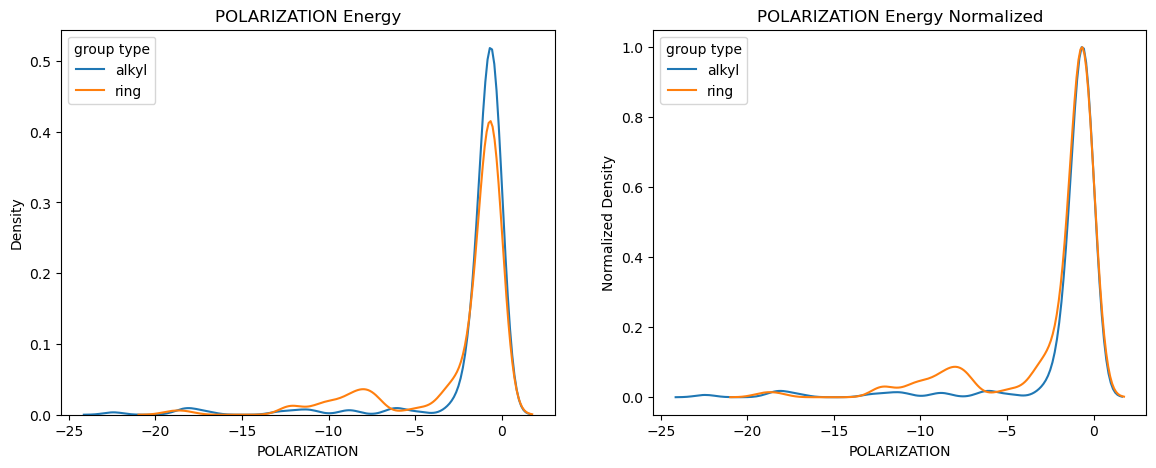

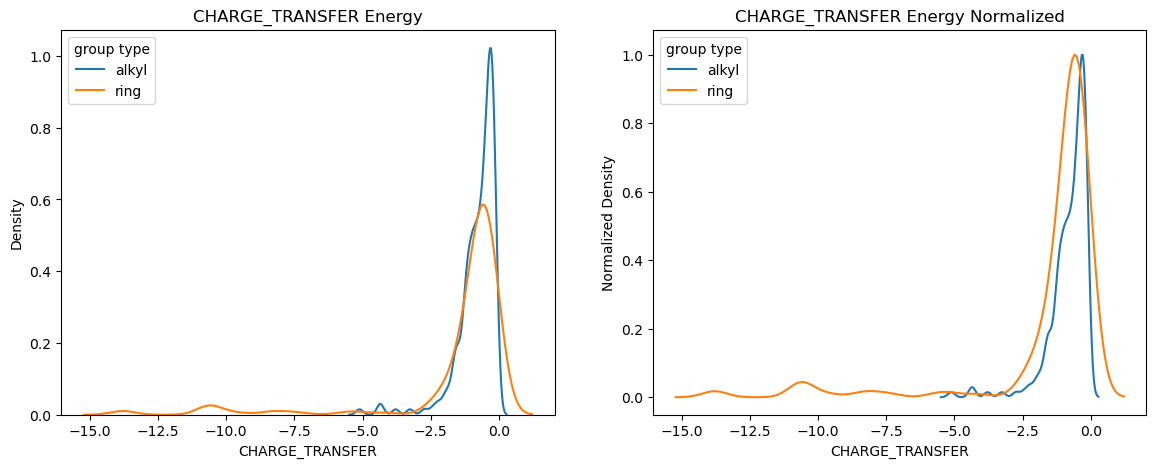

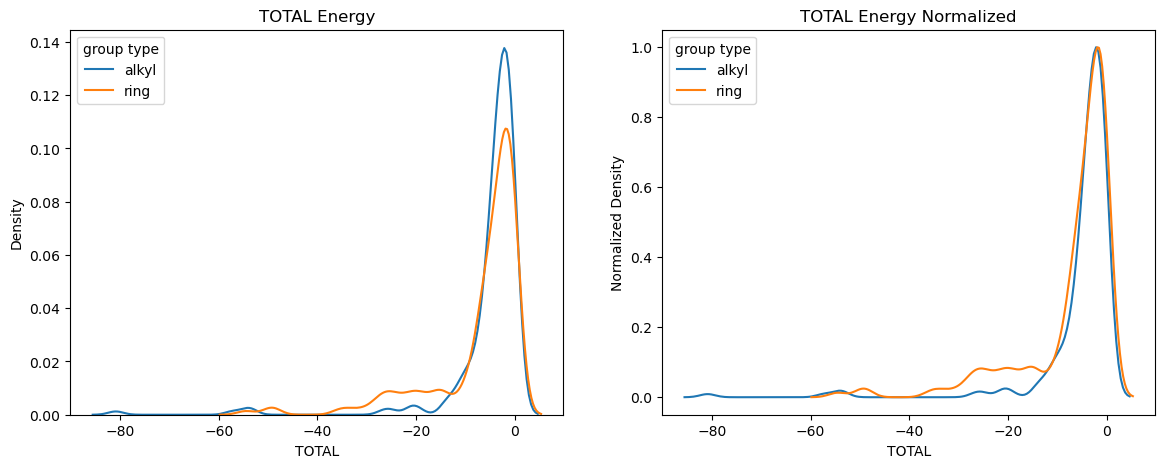

In [ ]:
df_F = df.query('donortype == "F" & TOTAL < 0')
labels = ['alkyl', 'ring']
items = [
    'FROZEN', 
    'CLS_ELEC', 
    'MOD_PAULI', 
    'DISP', 
    'POLARIZATION', 
    'CHARGE_TRANSFER', 
    'TOTAL'
]
for item in items:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    plot('dist', ('group', labels, item, palette), df_F, axes[0])
    plot('dist', ('group', labels, item, palette), df_F, axes[1], kde_norm=True)



In [ ]:
xlabels = ['2.6A - 2.8A', '2.8A - 3.0A', '3.0A - 3.2A', '3.2A - 3.4A', '3.4A - 3.6A', '3.6A - 3.8A', '3.8A - 4.0A']
items = [
    'CLS_ELEC', 
    # 'DISP', 
    # 'POLARIZATION', 
    # 'CHARGE_TRANSFER', 
    'TOTAL'
]

dists = np.arange(2.6, 4.2, 0.2).tolist()
data_F_alkyl = box_plot_data(F_alkyl, dists)
print(list(map(len, data_F_alkyl)))

fig, ax = plt.subplots(figsize=(16, 10))
plot('box', (dists, xlabels, items), F_alkyl, ax, plot=True)
ax.set_title('Box Plot F Alkyl group')


data_F_ring = box_plot_data(F_ring, dists)
print(list(map(len, data_F_ring)))

fig, ax = plt.subplots(figsize=(16, 10))
plot('box', (dists, xlabels, items), F_ring, ax, plot=True)
ax.set_title('Box Plot F Aromatic group')

NameError: name 'F_alkyl' is not defined